# Final Exam Project: Mathematical Modeling of Aggregate Working Time (SIRV) and Payroll Automation
## Course: Mathematics for Data Science
**Author:** Gergana Vuleva  
**Target Month:** September 2026

### Introduction & Problem Formulation
In Bulgarian labor law, the calculation of aggregate working time (Сумирано изчисляване на работното време - СИРВ) presents a significant logistical and mathematical challenge for payroll departments. Companies with 24/7 production cycles must optimize shift schedules while strictly complying with the Labor Code (Кодекс на труда - КТ).

This project aims to translate the statutory TZR rules into a mathematical and programmatic model using Python. 

### Calendar Specifics for September 2026:
* Total calendar days: 30
* Official holidays: September 6th (Unification Day) falls on a Sunday, which makes September 7th (Monday) a non-working day by law (Art. 154, al. 2 of KT). September 22nd (Independence Day) is a Tuesday (official holiday).
* Standard working days: 20 days
* Monthly norm for a standard 8-hour shift: **160 hours** (20 days * 8 hours).


In [1]:
import pandas as pd
import numpy as np

# Establishing the structural math constants for September 2026 TRZ norm
MONTHLY_NORM_HOURS = 160  # 20 working days * 8 hours
NIGHT_TO_DAY_COEFFICIENT = 1.143  # 8 hour / 7 hour = 1,142857 According to NRVPU for transforming night hours
NIGHT_PREMIUM_PER_HOUR = 0.93  # 0,15% of minimum wage - Statutory minimum premium per night hour in EUR

print(f"[INFO] Mathematical configuration loaded.")
print(f"Standard Monthly Norm: {MONTHLY_NORM_HOURS} hours.")
print(f"Night Shift Coefficient: {NIGHT_TO_DAY_COEFFICIENT}")


[INFO] Mathematical configuration loaded.
Standard Monthly Norm: 160 hours.
Night Shift Coefficient: 1.143


### Mathematical Representation of the Workforce
We represent our employee database as a structural matrix (or DataFrame) where each entity possesses an explicit base salary and contract conditions. We will model a team of 5 employees working on shifts under the SIVR regime [[1]](#ref1).


In [2]:
# Initializing employee master data card index
employees_data = {
    'Employee_ID': ['101', '102', '103', '104', '105'],
    'Name': ['Dimitar Petrov', 'Elena Georgieva', 'Ivan Todorov', 'Maria Vasileva', 'Nikolay Ivanov'],
    'Position': ['Shift Leader', 'Machine Operator', 'Machine Operator', 'Warehouse Worker', 'Warehouse Worker'],
    'Base_Salary': [2400.00, 1950.00, 1950.00, 1800.00, 1800.00]
}

df_payroll = pd.DataFrame(employees_data)
df_payroll



,Employee_ID,Name,Position,Base_Salary
0,101,Dimitar Petrov,Shift Leader,2400.0
1,102,Elena Georgieva,Machine Operator,1950.0
2,103,Ivan Todorov,Machine Operator,1950.0
3,104,Maria Vasileva,Warehouse Worker,1800.0
4,105,Nikolay Ivanov,Warehouse Worker,1800.0


### Shift Schedule Matrix Integration
We simulate the actual time-sheet (форма 76) data for the month. Under SIVR, employees work various combinations of day hours, night hours (22:00 - 06:00), and holiday shifts [[2]](#ref2).


In [3]:
# Inputting actual clocked hours from the shift schedule timesheet
df_payroll['Hours_Day'] = [132, 120, 110, 140, 120]
df_payroll['Hours_Night'] = [24, 32, 40, 16, 36]
df_payroll['Hours_Holiday'] = [12, 0, 8, 0, 12]  # Hours clocked on Sep 6 or Sep 22

df_payroll


,Employee_ID,Name,Position,Base_Salary,Hours_Day,Hours_Night,Hours_Holiday
0,101,Dimitar Petrov,Shift Leader,2400.0,132,24,12
1,102,Elena Georgieva,Machine Operator,1950.0,120,32,0
2,103,Ivan Todorov,Machine Operator,1950.0,110,40,8
3,104,Maria Vasileva,Warehouse Worker,1800.0,140,16,0
4,105,Nikolay Ivanov,Warehouse Worker,1800.0,120,36,12


### Mathematical Transformation: Night Hours to Day Hours Conversion
According to Bulgarian legislation (НРВПУ), when calculating overtime at the end of an SIVR period, night hours must be multiplied by a factor of $1.143$ to align them with standard daytime hours.[4]

$$\text{Transformed Night Hours} = \text{Hours\_Night} \times 1.143$$
$$\text{Total Equalized Hours} = \text{Hours\_Day} + \text{Transformed Night Hours}$$


In [4]:
# Applying the mathematical conversion for night shift hours [4]
df_payroll['Transformed_Night_Hours'] = round(df_payroll['Hours_Night'] * NIGHT_TO_DAY_COEFFICIENT, 2)

# Calculating total equalized hours for comparison against the monthly norm
df_payroll['Total_Equalized_Hours'] = df_payroll['Hours_Day'] + df_payroll['Transformed_Night_Hours']

df_payroll[['Name', 'Hours_Night', 'Transformed_Night_Hours', 'Total_Equalized_Hours']]



,Name,Hours_Night,Transformed_Night_Hours,Total_Equalized_Hours
0,Dimitar Petrov,24,27.43,159.43
1,Elena Georgieva,32,36.58,156.58
2,Ivan Todorov,40,45.72,155.72
3,Maria Vasileva,16,18.29,158.29
4,Nikolay Ivanov,36,41.15,161.15


### Overtime Calculation Logic under SIVR
Overtime ($\text{Overtime\_Hours}$) occurs when the total equalized hours exceed the statutory monthly norm (`160` hours) determined by the working calendar [[2]](#ref2). 

We can define this mathematically using a piecewise function [[6]](#ref6):
$$
\text{Overtime\_Hours} = 
\begin{cases} 
\text{Total\_Equalized\_Hours} - 160 & \text{if } \text{Total\_Equalized\_Hours} > 160 \\
0 & \text{otherwise}
\end{cases}
$$



In [5]:
# Computing overtime hours using a vectorized numpy condition
df_payroll['Overtime_Hours'] = np.where(
    df_payroll['Total_Equalized_Hours'] > MONTHLY_NORM_HOURS,
    round(df_payroll['Total_Equalized_Hours'] - MONTHLY_NORM_HOURS, 2),
    0.0
)

df_payroll[['Name', 'Total_Equalized_Hours', 'Overtime_Hours']]


,Name,Total_Equalized_Hours,Overtime_Hours
0,Dimitar Petrov,159.43,0.00
1,Elena Georgieva,156.58,0.00
2,Ivan Todorov,155.72,0.00
3,Maria Vasileva,158.29,0.00
4,Nikolay Ivanov,161.15,1.15


### Payroll Calculations: Remuneration Components
Now, we calculate the financial accruals based on standard accounting and labor practices:
1. **Base Hourly Rate:** $\text{Hourly\_Rate} = \frac{\text{Base\_Salary}}{160}$
2. **Night Premium:** Additional payment for hours clocked between 22:00 and 06:00, meeting the statutory minimum [[4]](#ref4).
3. **Holiday Pay:** Hours worked on official public holidays are paid at a premium rate addition of $1.0$ (effectively double rate) [[5]](#ref5).
4. **Overtime Pay:** For SIVR, overtime hours are compensated with a premium rate coefficient of $0.5$ addition [[6]](#ref6).



In [6]:
# Calculate basic hourly rate for each employee
df_payroll['Hourly_Rate'] = round(df_payroll['Base_Salary'] / MONTHLY_NORM_HOURS, 4)

# Calculate statutory night shift additions
df_payroll['Night_Bonus_Pay'] = round(df_payroll['Hours_Night'] * NIGHT_PREMIUM_PER_HOUR, 2)

# Calculate holiday premium pay (Hours * Hourly Rate * 1.0 premium addition)
df_payroll['Holiday_Premium_Pay'] = round(df_payroll['Hours_Holiday'] * df_payroll['Hourly_Rate'] * 1.0, 2)

# Calculate overtime premium pay (Overtime Hours * Hourly Rate * 0.5 premium addition)
df_payroll['Overtime_Premium_Pay'] = round(df_payroll['Overtime_Hours'] * df_payroll['Hourly_Rate'] * 0.5, 2)

df_payroll[['Name', 'Hourly_Rate', 'Night_Bonus_Pay', 'Holiday_Premium_Pay', 'Overtime_Premium_Pay']]


,Name,Hourly_Rate,Night_Bonus_Pay,Holiday_Premium_Pay,Overtime_Premium_Pay
0,Dimitar Petrov,15.0000,22.32,180.0,0.00
1,Elena Georgieva,12.1875,29.76,0.0,0.00
2,Ivan Todorov,12.1875,37.20,97.5,0.00
3,Maria Vasileva,11.2500,14.88,0.0,0.00
4,Nikolay Ivanov,11.2500,33.48,135.0,6.47


### Total Gross Salary Accumulation
The total gross salary ($\text{Gross\_Salary}$) is the sum of the standard base contract salary and all mathematically derived labor premiums.

$$\text{Gross\_Salary} = \text{Base\_Salary} + \text{Night\_Bonus\_Pay} + \text{Holiday\_Premium\_Pay} + \text{Overtime\_Premium\_Pay}$$


In [7]:
# Accumulating all components to find the absolute Gross Salary
df_payroll['Gross_Salary'] = round(
    df_payroll['Base_Salary'] + 
    df_payroll['Night_Bonus_Pay'] + 
    df_payroll['Holiday_Premium_Pay'] + 
    df_payroll['Overtime_Premium_Pay'], 
    2
)

# Printing final optimized accounting payroll ledger
final_ledger = df_payroll[['Name', 'Position', 'Base_Salary', 'Overtime_Hours', 'Gross_Salary']]
final_ledger


,Name,Position,Base_Salary,Overtime_Hours,Gross_Salary
0,Dimitar Petrov,Shift Leader,2400.0,0.00,2602.32
1,Elena Georgieva,Machine Operator,1950.0,0.00,1979.76
2,Ivan Todorov,Machine Operator,1950.0,0.00,2084.70
3,Maria Vasileva,Warehouse Worker,1800.0,0.00,1814.88
4,Nikolay Ivanov,Warehouse Worker,1800.0,1.15,1974.95


### Data Visualization and Accounting Analysis
Visualizing the distribution of total labor costs across different corporate positions to provide actionable financial insight for budget allocation.


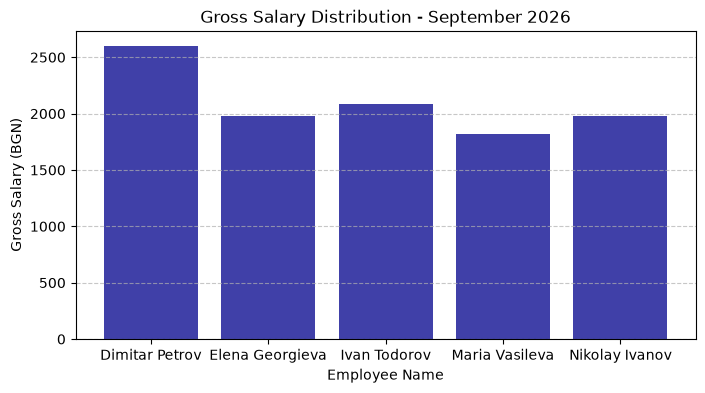

In [8]:
import matplotlib.pyplot as plt

# Plotting Gross Salary spending per employee position
plt.figure(figsize=(8, 4))
plt.bar(df_payroll['Name'], df_payroll['Gross_Salary'], color='darkblue', alpha=0.75)
plt.title('Gross Salary Distribution - September 2026')
plt.xlabel('Employee Name')
plt.ylabel('Gross Salary (BGN)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### Conclusion
By mapping the statutory rules of the Bulgarian Labor Code into a programmable script, we have successfully minimized human calculation errors in SIVR. The application of linear conversions and conditional piecewise modeling ensures precise and lawful payroll outcomes.

---

### 📚 References & Statutory Sources
* <a id="ref1"></a>**[1] Labor Code of Bulgaria (КТ) - Art. 142, al. 2:** Rules regarding the establishment of aggregate working time (СИРВ) by the employer.  
* <a id="ref2"></a>**[2] Labor Code of Bulgaria (КТ) - Art. 154, al. 1 & al. 2:** Defines official public holidays and dictates that when a holiday falls on a Sunday, the following Monday is a non-working day (applied to September 6th and 7th, 2026).  
* <a id="ref3"></a>**[3] Regulation on Working Time, Rests, and Leaves (НРВПУ) - Art. 9, al. 2:** Establishes the mathematical 1.143 coefficient for converting night hours (22:00 to 06:00) into day hours under the SIVR regime.  
* <a id="ref4"></a>**[4] Regulation on Structure and Organisation of Salary (НСОЗ) - Art. 7:** Defines the statutory minimum additional pay per hour for night labor.  
* <a id="ref5"></a>**[5] Labor Code of Bulgaria (КТ) - Art. 264:** Mandates that work performed on official public holidays must be compensated with a minimum premium of 100% (double pay).  
* <a id="ref6"></a>**[6] Labor Code of Bulgaria (КТ) - Art. 262, al. 1, pt. 4:** Explicitly dictates that overtime accrued under the SIVR system is compensated with a 50% premium addition at the end of the calculation period.



